# Three-way overlap on gold DILI: MMP × Caspase-3/7 × clinical DILI (HepG2)

**Question.** Among gold-standard clinical DILI compounds, does being active in the HepG2
MMP and/or Caspase-3/7 assay go together with being DILI-positive?

**Labels.**
- DILI label = `TOXICITY` from the gold sets **NCV-888** and **Held-223** (Gold-1111 = both).
- Assay label = PubChem `Active` / `Inactive` from the cleaned HepG2 assay CSVs
  (MMP AID 720637, Caspase-3/7 AID 1347034).
- Compounds are matched by **InChIKey**, computed from each assay's SMILES with RDKit.

The analysis is shown twice:
- **Part A — measured only:** a compound counts only if it was actually tested.
- **Part B — measured + predicted:** untested compounds get a label from the consensus
  assay model, so all gold compounds are included.
- **Part C — predicted only:** every gold compound, measured or not, gets the
  consensus-model label.

Run from the `DILI_assay_link/` folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from rdkit import Chem, RDLogger
RDLogger.DisableLog('rdApp.*')

def to_inchikey(smi):
    mol = Chem.MolFromSmiles(str(smi))
    return Chem.MolToInchiKey(mol) if mol else None


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/yamini/Library/Python/3.9/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/yami

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/yamini/Library/Python/3.9/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/yami

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/yamini/Library/Python/3.9/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/yami

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/yamini/Library/Python/3.9/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/yami

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/yamini/Library/Python/3.9/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/yami

AttributeError: _ARRAY_API not found

## 1. Gold DILI compounds (true clinical labels)

A compound listed in both sets is kept once, under Held-223 (the test set).

In [2]:
held = pd.read_csv('inputs/Held-223_deduped.csv', usecols=['InChIKey', 'TOXICITY'])
ncv  = pd.read_csv('inputs/NCV-888_deduped.csv',  usecols=['InChIKey', 'TOXICITY'])
held['set'], ncv['set'] = 'Held-223', 'NCV-888'

gold = (pd.concat([held, ncv]).dropna(subset=['InChIKey'])
          .drop_duplicates('InChIKey')             # Held-223 wins a tie
          .rename(columns={'TOXICITY': 'dili'}).set_index('InChIKey'))

print(gold.groupby('set').dili.agg(n='size', dili_pos='sum'))
print(f'\nGold total: {len(gold)}   DILI+ rate {gold.dili.mean():.1%}')

            n  dili_pos
set                    
Held-223  223       156
NCV-888   875       554

Gold total: 1098   DILI+ rate 64.7%


## 2. HepG2 assay labels (measured)

Keep `Active` (1) / `Inactive` (0), drop `Inconclusive`. If one InChIKey appears more than
once, take the majority label; an exact tie is dropped.

In [3]:
ASSAYS = {
    'mmp':     'inputs/AID_720637_cleaned.csv',        # MMP, HepG2
    'caspase': 'inputs/AID_1347034_cleaned.csv',       # Caspase-3/7, HepG2
}
NAME = {'mmp': 'MMP', 'caspase': 'Caspase-3/7'}

def load_assay(path):
    d = pd.read_csv(path, usecols=['PUBCHEM_EXT_DATASOURCE_SMILES', 'PUBCHEM_ACTIVITY_OUTCOME'])
    d = d[d.PUBCHEM_ACTIVITY_OUTCOME.isin(['Active', 'Inactive'])]
    d['ikey'] = d.PUBCHEM_EXT_DATASOURCE_SMILES.map(to_inchikey)
    d['y'] = (d.PUBCHEM_ACTIVITY_OUTCOME == 'Active').astype(int)
    m = d.dropna(subset=['ikey']).groupby('ikey').y.mean()
    return (m[m != 0.5] > 0.5).astype(int)        # majority vote, ties dropped

lab = {a: load_assay(p) for a, p in ASSAYS.items()}
for a, s in lab.items():
    print(f'{NAME[a]:12s} {len(s):5d} compounds, {s.sum():4d} active')

MMP           5935 compounds,  857 active
Caspase-3/7   7270 compounds,  303 active


## 3. How many gold compounds were measured in each assay?

In [4]:
SETS = {'Held-223 (test)': gold[gold.set == 'Held-223'].index,
        'NCV-888 (train)': gold[gold.set == 'NCV-888'].index,
        'Gold-1111':       gold.index}

rows = []
for s, ik in SETS.items():
    r = {'DILI set': s}
    for a in lab:
        k = ik.isin(lab[a].index).sum()
        r[f'{NAME[a]} overlap'] = f'{100 * k / len(ik):.1f}% ({k}/{len(ik)})'
    rows.append(r)
pd.DataFrame(rows).set_index('DILI set')

,MMP overlap,Caspase-3/7 overlap
DILI set,,
Held-223 (test),27.8% (62/223),35.4% (79/223)
NCV-888 (train),19.2% (168/875),26.1% (228/875)
Gold-1111,20.9% (230/1098),28.0% (307/1098)


## 4. Plotting and testing helpers

`plot_three_way` draws the two panels. Left: count of each DILI-caspase-MMP combination
(1 = positive/active). Right: DILI-positive rate in each caspase/MMP cell, with the base
rate dashed. `fisher_table` tests each assay against DILI.

In [5]:
INK, MUTED, GRID = '#1f2933', '#7b8794', '#dfe3e8'
BAR, BAR_HI = '#8aa4c8', '#2f5d8c'
LBL = {(0, 0): 'neither\nactive', (1, 0): 'caspase only',
       (0, 1): 'MMP only', (1, 1): 'both\nactive'}

def plot_three_way(df, left_title, suptitle, fname):
    key = df.dili.astype(str) + '-' + df.caspase.astype(str) + '-' + df.mmp.astype(str)
    idx = [f'{d}-{c}-{m}' for d in (0, 1) for c in (0, 1) for m in (0, 1)]
    counts = key.value_counts().reindex(idx, fill_value=0)

    g = df.groupby(['caspase', 'mmp']).dili.agg(n='size', pos='sum')
    g = g.reindex(list(LBL), fill_value=0)
    g['rate'] = g.pos / g.n.where(g.n > 0, 1)
    base = 100 * df.dili.mean()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

    ax1.bar(counts.index, counts.values, width=0.68, zorder=3,
            color=[BAR_HI if i == '1-1-1' else BAR for i in counts.index])
    for x, v in enumerate(counts.values):
        ax1.text(x, v * 1.12 if v else 1.12, f'{v:,}', ha='center', va='bottom',
                 fontsize=8.5, color=INK)
    ax1.set_yscale('symlog', linthresh=1)
    ax1.set_ylim(0, counts.max() * 4)
    ax1.set_xticks(range(8))
    ax1.set_xticklabels(counts.index, rotation=45, ha='right')
    ax1.set_title(left_title, fontsize=10, color=INK, pad=8)
    ax1.set_xlabel('DILI-caspase-MMP', fontsize=9, color=MUTED)
    ax1.set_ylabel('compounds (log scale)', fontsize=9, color=MUTED)

    ax2.bar([LBL[i] for i in g.index], 100 * g.rate, width=0.62, zorder=3,
            color=[BAR_HI if i == (1, 1) else BAR for i in g.index])
    ax2.axhline(base, color=INK, ls='--', lw=1.2, zorder=4)
    ax2.text(int(np.argmax(np.abs(100 * g.rate.values - base))), base + 1.5,
             f'base {base:.1f}%', ha='center', fontsize=8.5, color=INK)
    for x, (r, n) in enumerate(zip(g.rate, g.n)):
        ax2.text(x, 100 * r + 2, f'{100 * r:.0f}%  (n={n})', ha='center', va='bottom',
                 fontsize=9, color=INK, zorder=6,
                 bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none'))
    ax2.set_ylim(0, 112)
    ax2.set_title('DILI-positive rate by in vitro pattern', fontsize=10, color=INK, pad=8)
    ax2.set_ylabel('DILI-positive rate (%)', fontsize=9, color=MUTED)

    for ax in (ax1, ax2):
        ax.tick_params(colors=MUTED, labelsize=8.5)
        ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
        for s in ('left', 'bottom'):
            ax.spines[s].set_color(GRID)

    fig.suptitle(suptitle, fontsize=11, color=INK, y=1.02)
    fig.tight_layout()
    fig.savefig(f'results/{fname}', dpi=200, bbox_inches='tight')
    plt.show()
    print(counts.rename('count').to_frame().T.to_string())

def fisher_table(df, cols):
    for a in ('mmp', 'caspase'):
        d = df.dropna(subset=[cols[a]])
        ct = pd.crosstab(d[cols[a]].astype(int), d.dili).reindex(
            index=[0, 1], columns=[0, 1], fill_value=0)
        odds, p = stats.fisher_exact(ct.values)
        print(f'{NAME[a]:12s} n={len(d):4d}   '
              f'DILI+ if inactive {ct.loc[0, 1] / ct.loc[0].sum():5.1%} (n={ct.loc[0].sum()})   '
              f'DILI+ if ACTIVE {ct.loc[1, 1] / ct.loc[1].sum():5.1%} (n={ct.loc[1].sum()})   '
              f'OR {odds:.2f}  p={p:.3g}')

---
# Part A — measured labels only

## A1. Gold compounds measured in both HepG2 assays

In [6]:
meas = gold.copy()
for a in lab:
    meas[a] = lab[a].reindex(meas.index)

tri = meas.dropna(subset=['caspase', 'mmp']).astype({'caspase': int, 'mmp': int})
print(f'Gold compounds measured in BOTH HepG2 assays: {len(tri)}')
print(f'  MMP active {tri.mmp.sum()},  caspase active {tri.caspase.sum()},  '
      f'both {((tri.mmp == 1) & (tri.caspase == 1)).sum()}')
print(f'  DILI+ rate {tri.dili.mean():.1%}')

Gold compounds measured in BOTH HepG2 assays: 197
  MMP active 19,  caspase active 3,  both 2
  DILI+ rate 67.0%


## A2. Figure (measured only)

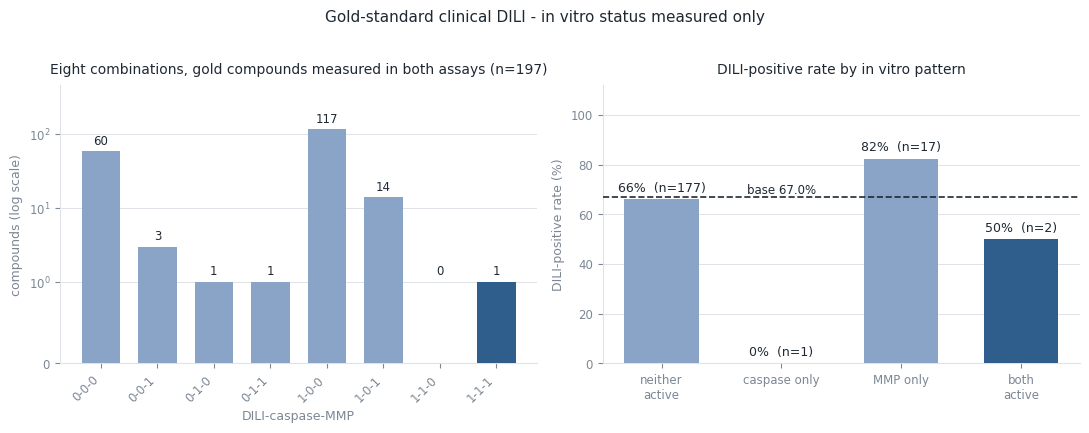

       0-0-0  0-0-1  0-1-0  0-1-1  1-0-0  1-0-1  1-1-0  1-1-1
count     60      3      1      1    117     14      0      1


In [7]:
plot_three_way(tri,
               f'Eight combinations, gold compounds measured in both assays (n={len(tri)})',
               'Gold-standard clinical DILI - in vitro status measured only',
               'gold_three_way_measured.png')

## A3. Fisher's exact test (measured only)

Each assay is tested on every gold compound measured in it, so n is larger than the
three-way set above.

In [8]:
fisher_table(meas, {'mmp': 'mmp', 'caspase': 'caspase'})

MMP          n= 230   DILI+ if inactive 64.9% (n=205)   DILI+ if ACTIVE 76.0% (n=25)   OR 1.71  p=0.371
Caspase-3/7  n= 307   DILI+ if inactive 70.6% (n=286)   DILI+ if ACTIVE 71.4% (n=21)   OR 1.04  p=1


---
# Part B — measured + predicted labels

Most gold compounds were never tested. Here an untested compound gets a 0/1 label from
the consensus assay model (`results/invitro_features.csv`, `mmp_prob` / `caspase_prob`;
out-of-bag, so a measured compound's own label never leaked into its prediction).

## B1. Choose a cutoff for each model

The cutoff is the Youden-J point of the ROC curve, fitted on the gold compounds that
were actually measured.

In [9]:
prob = pd.read_csv('results/invitro_features.csv',
                   usecols=['InChIKey', 'mmp_prob', 'caspase_prob']).set_index('InChIKey')

thresh = {}
for a in lab:
    m = pd.concat([lab[a].rename('y'), prob[f'{a}_prob']], axis=1, join='inner')
    m = m[m.index.isin(gold.index)]
    fpr, tpr, cuts = roc_curve(m.y, m[f'{a}_prob'])
    thresh[a] = float(cuts[np.argmax(tpr - fpr)])
    print(f'{NAME[a]:12s} measured gold n={len(m):3d} (active {m.y.sum():2d})   '
          f'ROC-AUC {roc_auc_score(m.y, m[f"{a}_prob"]):.3f}   cutoff {thresh[a]:.3f}')

MMP          measured gold n=230 (active 25)   ROC-AUC 0.959   cutoff 0.549
Caspase-3/7  measured gold n=307 (active 21)   ROC-AUC 0.936   cutoff 0.268


## B2. Hybrid labels: measured where available, predicted otherwise

In [10]:
hyb = gold.join(prob, how='inner')
for a in lab:
    measured = lab[a].reindex(hyb.index)
    predicted = (hyb[f'{a}_prob'] >= thresh[a]).astype(int)
    hyb[a] = measured.fillna(predicted).astype(int)
    print(f'{NAME[a]:12s} {measured.notna().sum():4d} measured + '
          f'{measured.isna().sum():4d} predicted = {len(hyb)}   active {hyb[a].sum()}')
print(f'\nDILI+ rate {hyb.dili.mean():.1%}')

MMP           230 measured +  866 predicted = 1096   active 181
Caspase-3/7   307 measured +  789 predicted = 1096   active 258

DILI+ rate 64.6%


## B3. Figure (measured + predicted)

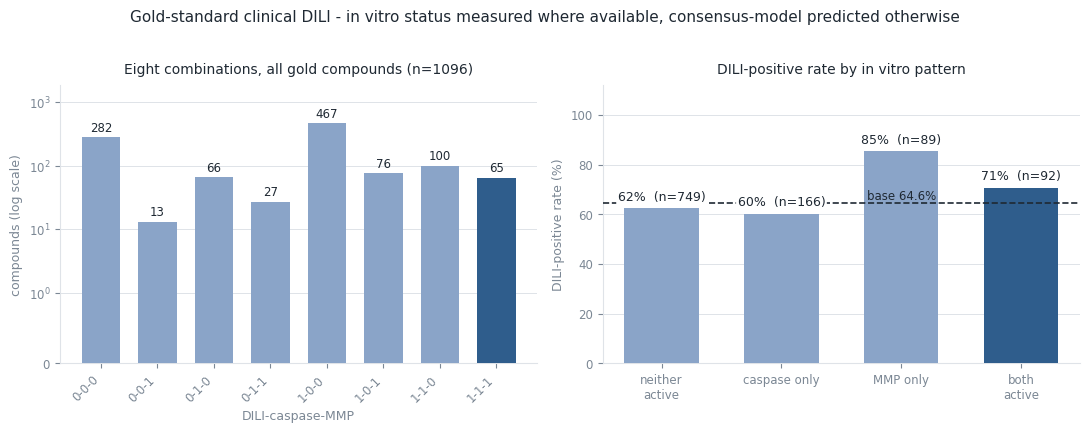

       0-0-0  0-0-1  0-1-0  0-1-1  1-0-0  1-0-1  1-1-0  1-1-1
count    282     13     66     27    467     76    100     65


In [11]:
plot_three_way(hyb,
               f'Eight combinations, all gold compounds (n={len(hyb)})',
               'Gold-standard clinical DILI - in vitro status measured where available, '
               'consensus-model predicted otherwise',
               'gold_three_way_hybrid.png')

## B4. Fisher's exact test (measured + predicted)

In [12]:
fisher_table(hyb, {'mmp': 'mmp', 'caspase': 'caspase'})

MMP          n=1096   DILI+ if inactive 62.0% (n=915)   DILI+ if ACTIVE 77.9% (n=181)   OR 2.16  p=2.89e-05
Caspase-3/7  n=1096   DILI+ if inactive 64.8% (n=838)   DILI+ if ACTIVE 64.0% (n=258)   OR 0.96  p=0.823


---
# Part C — predicted labels only

Every gold compound gets its label from the consensus assay model, **including the ones
that were measured** (measured labels are ignored). Same Youden-J cutoffs as B1.

## C1. Predicted labels for all gold compounds

In [13]:
pred = gold.join(prob, how='inner')
for a in lab:
    pred[a] = (pred[f'{a}_prob'] >= thresh[a]).astype(int)
    agree = pd.concat([lab[a].rename('y'), pred[a]], axis=1, join='inner')
    print(f'{NAME[a]:12s} {len(pred)} predicted   active {pred[a].sum()}   '
          f'agrees with measured on {(agree.y == agree[a]).mean():.1%} of {len(agree)}')
print(f'\nDILI+ rate {pred.dili.mean():.1%}')

MMP          1096 predicted   active 188   agrees with measured on 95.2% of 230
Caspase-3/7  1096 predicted   active 300   agrees with measured on 85.0% of 307

DILI+ rate 64.6%


## C2. Figure (predicted only)

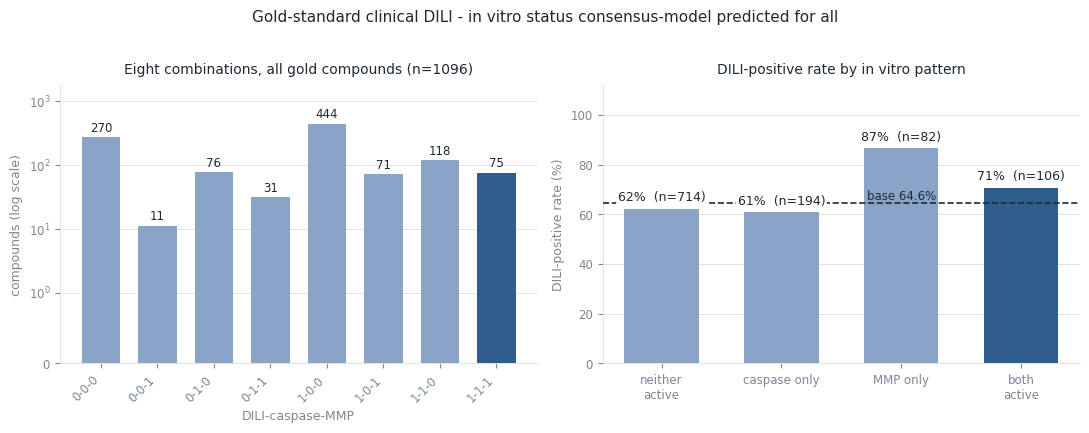

       0-0-0  0-0-1  0-1-0  0-1-1  1-0-0  1-0-1  1-1-0  1-1-1
count    270     11     76     31    444     71    118     75


In [14]:
plot_three_way(pred,
               f'Eight combinations, all gold compounds (n={len(pred)})',
               'Gold-standard clinical DILI - in vitro status consensus-model predicted for all',
               'gold_three_way_predicted.png')

## C3. Fisher's exact test (predicted only)

In [15]:
fisher_table(pred, {'mmp': 'mmp', 'caspase': 'caspase'})

MMP          n=1096   DILI+ if inactive 61.9% (n=908)   DILI+ if ACTIVE 77.7% (n=188)   OR 2.14  p=2.65e-05
Caspase-3/7  n=1096   DILI+ if inactive 64.7% (n=796)   DILI+ if ACTIVE 64.3% (n=300)   OR 0.98  p=0.944


## What this shows

| | Part A: measured only | Part B: measured + predicted | Part C: predicted only |
|---|---|---|---|
| Gold compounds in the three-way set | 197 | 1,096 | 1,096 |
| Active in both assays (1-1-1 + 0-1-1) | 2 | 92 | 106 |
| **MMP** active vs inactive, DILI+ rate | 76% vs 65%, OR 1.71, p = 0.37 | 78% vs 62%, **OR 2.16, p = 2.9e-5** | 78% vs 62%, **OR 2.14, p = 2.7e-5** |
| **Caspase-3/7** active vs inactive, DILI+ rate | 71% vs 71%, OR 1.04, p = 1.0 | 64% vs 65%, OR 0.96, p = 0.82 | 64% vs 65%, OR 0.98, p = 0.94 |

- **MMP:** the direction is the same in both parts (MMP-active compounds are more often
  DILI+). It reaches significance only once predicted labels fill in the ~80% of gold
  compounds that were never tested, so it rests mostly on the MMP model.
- **Caspase-3/7:** no association with DILI in either part.
- **Both active:** too rare among measured compounds (n = 2) to say anything; the 92 in
  Part B are almost entirely model-predicted.
- **Predicted only (Part C):** essentially the same as Part B. The models agree with the
  measured label on 95% (MMP) and 85% (caspase) of measured gold compounds, so swapping
  measured for predicted labels barely moves the counts or the tests.